# Mosta Embyro Data

In [1]:
from STalign import STalign
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import plotly
import requests
import scanpy as sc
import matplotlib
import os

import warnings
warnings.filterwarnings("ignore")

## Load Data

In [2]:
# load Merfish mouse brain 33 data
file_path = './embryo_data/E11.5_E1S3.MOSTA.h5ad'
file_path2 = './embryo_data/E11.5_E1S4.MOSTA.h5ad'

ad = sc.read(file_path2)
ad_target = sc.read(file_path)

Only considering the two last: ['.MOSTA', '.h5ad'].
Only considering the two last: ['.MOSTA', '.h5ad'].
Only considering the two last: ['.MOSTA', '.h5ad'].
Only considering the two last: ['.MOSTA', '.h5ad'].


In [3]:
ad.obs['annotation'].unique()

['Head mesenchyme', 'Inner ear', 'Cavity', 'Connective tissue', 'Mesenchyme', ..., 'Jaw and tooth', 'Heart', 'Surface ectoderm', 'Liver', 'Cartilage primordium']
Length: 19
Categories (19, object): ['Brain', 'Branchial arch', 'Cartilage primordium', 'Cavity', ..., 'Sclerotome', 'Surface ectoderm', 'Sympathetic nerve', 'Urogenital ridge']

In [4]:
cluster1 = ad.obs['annotation'].unique()
cluster2 = ad_target.obs['annotation'].unique()
all_clusters = set(cluster1).union(set(cluster2))
all_clusters

{'Brain',
 'Branchial arch',
 'Cartilage primordium',
 'Cavity',
 'Choroid plexus',
 'Connective tissue',
 'Dermomyotome',
 'Dorsal root ganglion',
 'Facial nerve',
 'GI tract',
 'Head mesenchyme',
 'Heart',
 'Inner ear',
 'Jaw and tooth',
 'Liver',
 'Meninges',
 'Mesenchyme',
 'Sclerotome',
 'Spinal cord',
 'Surface ectoderm',
 'Sympathetic nerve',
 'Urogenital ridge'}

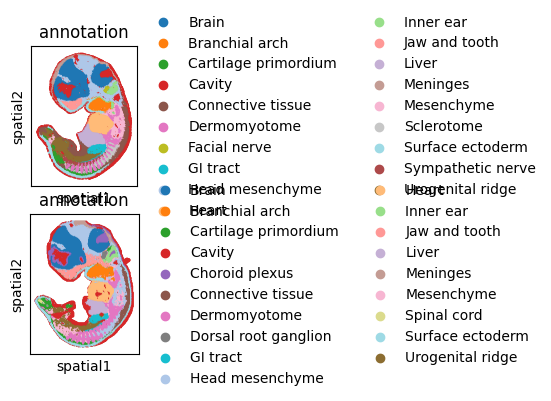

In [5]:
color_dict = {
    'Brain': '#1f77b4',
    'Branchial arch': '#ff7f0e',
    'Cartilage primordium': '#2ca02c',
    'Cavity': '#d62728',
    'Choroid plexus': '#9467bd',
    'Connective tissue': '#8c564b',
    'Dermomyotome': '#e377c2',
    'Dorsal root ganglion': '#7f7f7f',
    'Facial nerve': '#bcbd22',
    'GI tract': '#17becf',
    'Head mesenchyme': '#aec7e8',
    'Heart': '#ffbb78',
    'Inner ear': '#98df8a',
    'Jaw and tooth': '#ff9896',
    'Liver': '#c5b0d5',
    'Meninges': '#c49c94',
    'Mesenchyme': '#f7b6d2',
    'Sclerotome': '#c7c7c7',
    'Spinal cord': '#dbdb8d',
    'Surface ectoderm': '#9edae5',
    'Sympathetic nerve': '#ad494a',
    'Urogenital ridge': '#8c6d31'
}

fig, axes = plt.subplots(2, 1, figsize=(6, 4))
sc.pl.spatial(ad, color='annotation', spot_size=3, ax=axes[0], palette=color_dict, show=False)
sc.pl.spatial(ad_target, color='annotation', spot_size=3, ax=axes[1], palette=color_dict, show=False)
plt.show()

0 of 27455
10000 of 27455
20000 of 27455
27454 of 27455


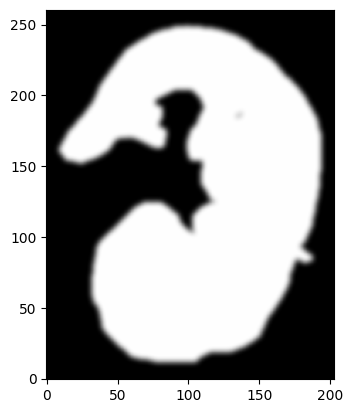

In [6]:
spatial_coords_target = ad_target.obsm['spatial']
x_target = spatial_coords_target[:, 0]
y_target = spatial_coords_target[:, 1]

# fig,ax = plt.subplots()

# rasterize at 30um resolution (assuming positions are in um units) and plot
XJ,YJ,J,fig = STalign.rasterize(x_target,y_target,dx=1,blur=1)

# plot
ax = fig.axes[0]
ax.invert_yaxis()

0 of 30775
10000 of 30775
20000 of 30775
30000 of 30775
30774 of 30775


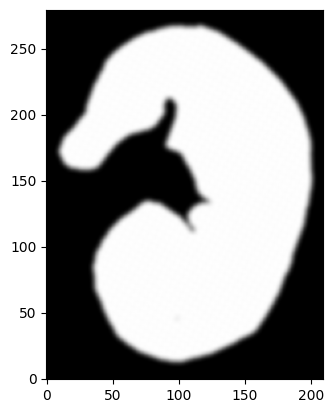

In [7]:
spatial_coords = ad.obsm['spatial']
x = spatial_coords[:, 0]
y = spatial_coords[:, 1]

# rasterize at 30um resolution (assuming positions are in um units) and plot
XI,YI,I,fig = STalign.rasterize(x,y,dx=1,blur=1)

# plot
ax = fig.axes[0]
ax.invert_yaxis()

In [8]:
x = x - 20
y = y + 180

x_target = x_target - 330
y_target = y_target + 550

In [9]:
XI,YI,I = STalign.rasterize(x,y,dx=1,blur=1,draw=0)
XJ,YJ,J = STalign.rasterize(x_target,y_target,dx=1,blur=1,draw=0)

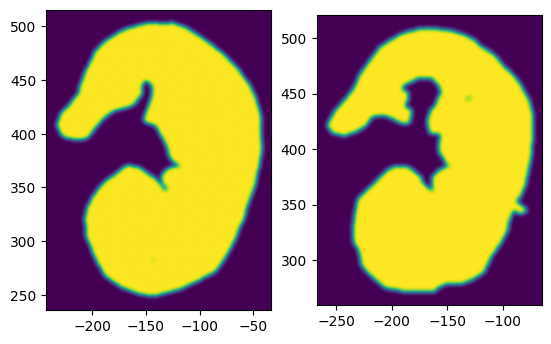

In [10]:
# get extent of images
extentI = STalign.extent_from_x((YI,XI))
extentJ = STalign.extent_from_x((YJ,XJ))

# plot rasterized images
fig,ax = plt.subplots(1,2)
ax[0].imshow(I[0], extent=extentI)
ax[1].imshow(J[0], extent=extentJ)
ax[0].invert_yaxis()
ax[1].invert_yaxis()

CPU times: user 11min 38s, sys: 8.29 s, total: 11min 46s
Wall time: 11min 45s


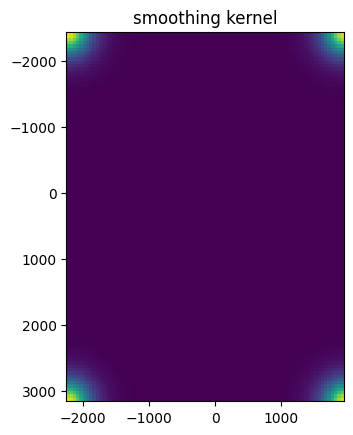

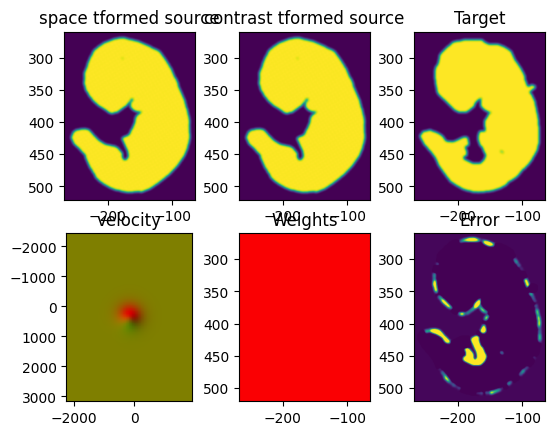

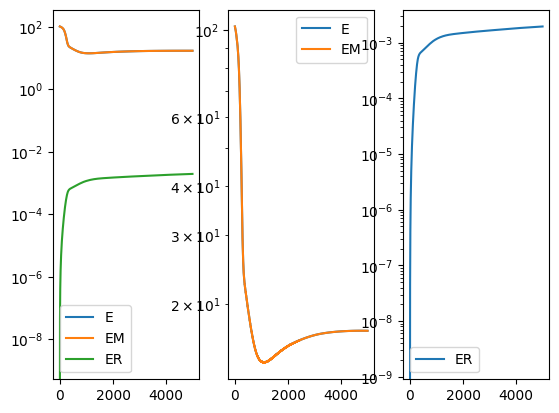

In [55]:
%%time
# run LDDMM
# specify device (default device for STalign.LDDMM is cpu)
if torch.cuda.is_available():
    device = 'cuda:0'
else:
    device = 'cpu'

# keep all other parameters default
params = {
#             'pointsI':pointsI,
#             'pointsJ':pointsJ,
#             'L':L,'T':T,
            'expand': 20.0,
            'a': 100,
            'niter':5000,
            'device':device,
            'epV': 10,
            'sigmaA': 5, #standard deviation of artifact intensities
            'sigmaB': 5, #standard deviation of background intensities
            'sigmaM': 5, #standard deviation of matching tissue intenities
          }

out = STalign.LDDMM([YI,XI],I,[YJ,XJ],J,**params)

In [56]:
# get necessary output variables
A = out['A']
v = out['v']
xv = out['xv']

In [57]:
pointsI = torch.tensor(np.stack([y, x], 1), device='cuda', dtype=torch.float64)

# apply transform to original points
tpointsI= STalign.transform_points_source_to_target(xv,v,A, pointsI)

#switch tensor from cuda to cpu for plotting with numpy
if tpointsI.is_cuda:
    tpointsI = tpointsI.cpu()

#switch from row column coordinates (y,x) to (x,y)
xI_LDDMM = tpointsI[:,1]
yI_LDDMM = tpointsI[:,0]

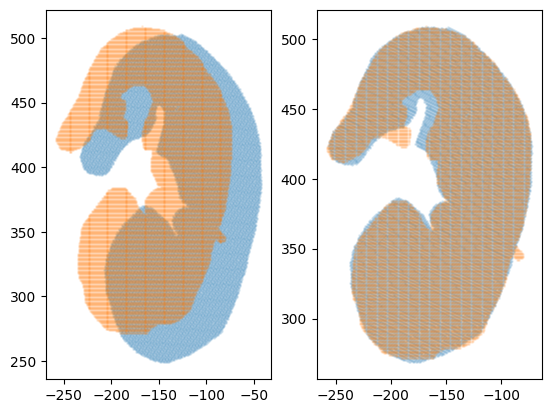

In [58]:
fig,ax = plt.subplots(1,2)
ax[0].scatter(x,y,s=1,alpha=0.1, label='source with initial affine transformation')
ax[0].scatter(x_target,y_target,s=1,alpha=0.1, label='target')
ax[1].scatter(xI_LDDMM,yI_LDDMM,s=1,alpha=0.1, label = 'source STaligned')
ax[1].scatter(x_target,y_target,s=1,alpha=0.1, label='target')
# ax[0].legend(markerscale = 10, loc = 'lower left')
# ax[1].legend(markerscale = 10, loc = 'lower left')

## LAA & ARI

In [61]:
from scipy.spatial import cKDTree
from sklearn.metrics import adjusted_rand_score


def find_nearest_points(f1, f2):
    """
    Find the nearest point in f2 for each point in f1 using batch processing.
    
    Args:
        f1 (numpy.ndarray): Array of shape (n_points_1, 2) representing points in f1.
        f2 (numpy.ndarray): Array of shape (n_points_2, 2) representing points in f2.
        batch_size (int): Number of points to process in each batch.
        
    """
    # Build a k-d tree for f2
    tree = cKDTree(f2)
    
    # Query the k-d tree for nearest neighbors of points in f1
    distances, nearest_indices = tree.query(f1)
        
    cnt = 0
    true_clusters_mapped_region = []
    mapped_clusters_mapped_region = []

    for i in range(len(f1)):
        f1_cluster = ad_target.obs.iloc[i]['annotation']
        f2_cluster = ad.obs.iloc[nearest_indices[i]]['annotation']
        true_clusters_mapped_region.append(f1_cluster)
        mapped_clusters_mapped_region.append(f2_cluster)
        if f1_cluster == f2_cluster:
            cnt += 1 

    laa = cnt/len(f2)
    ari = adjusted_rand_score(true_clusters_mapped_region, mapped_clusters_mapped_region)
              
    return laa,ari


In [62]:
f1 = np.column_stack((x_target, y_target))  # Shape: (n_points, 2)
f2 = np.column_stack((xI_LDDMM, yI_LDDMM))  # Shape: (n_points, 2)

laa,ari = find_nearest_points(f1, f2)

print(laa)
print(ari)

0.49510966693744923
0.3864531509218263


## 3D

In [64]:
dfs = ad.obs['annotation']

df1 = dfs.reset_index()
df1 = df1.rename(columns={'cell_name': 'index'})
df1 = df1.rename(columns={'annotation': 'original_clusters'})

df1.head()

,index,original_clusters
0,100_100,Head mesenchyme
1,100_101,Inner ear
2,100_102,Inner ear
3,100_103,Inner ear
4,100_104,Inner ear


In [65]:
df3_1 = pd.DataFrame(
    {
        "X": xI_LDDMM,
        "Y": yI_LDDMM,
    },
)

results1 = pd.concat([df1, df3_1], axis=1)
results1['Z'] = 3
results1['slice'] = '4'
results1

,index,original_clusters,X,Y,Z,slice
0,100_100,Head mesenchyme,-113.529060,324.423453,3,4
1,100_101,Inner ear,-113.161439,325.309673,3,4
2,100_102,Inner ear,-112.793987,326.195842,3,4
3,100_103,Inner ear,-112.426704,327.081959,3,4
4,100_104,Inner ear,-112.059589,327.968024,3,4
...,...,...,...,...,...,...
30770,99_95,Cavity,-114.462596,319.632664,3,4
30771,99_96,Cavity,-114.094323,320.519084,3,4
30772,99_97,Head mesenchyme,-113.726219,321.405452,3,4
30773,99_98,Head mesenchyme,-113.358284,322.291768,3,4


In [66]:
results1.to_csv("4.csv", index=False)

## Plot 3D


In [ ]:
# List of filenames
filenames = [f"E11.5_S{i}.csv" for i in range(1,5)]

# Read and combine CSV files
dfs = [pd.read_csv(file) for file in filenames]
combined_df = pd.concat(dfs, ignore_index=True)

# Display the combined DataFrame
combined_df


In [ ]:
# Combine unique clusters from all slices
unique_clusters = combined_df['original_clusters'].unique()
sorted_clusters = np.sort(unique_clusters)

cmap = []
if len(sorted_clusters) <= 10: # when no. of layers <=10
    for e in plt.get_cmap('tab10').colors:
        cmap.append(matplotlib.colors.rgb2hex(e))
else: # when 10< no. of layers <=60
    colormaps = ['tab20', 'tab20b', 'tab20c']
    for cmap_name in colormaps:
        for color in plt.get_cmap(cmap_name).colors:
            cmap.append(matplotlib.colors.rgb2hex(color))

# Create the dictionary with the combined clusters
c_dict = dict(zip(sorted_clusters, cmap))
c_dict

In [ ]:
combined_df['celltype_colors'] = combined_df['original_clusters'].replace(c_dict)
# combined_df.to_csv('STalign_embryo_E11.5_S1_S4_aligned_coordinates_colors.csv', index=False)

In [3]:
def plot_3d(
    loc,
    val=None,
    color=None,
    figsize=(12,12),
    return_fig=True,
    elev=None,
    azim=None,
    roll=None,
    xlim=None,
    ylim=None,
    zlim=None,
    frameon=True,
    save_path=None,
    save_dpi=150,
    show=True,
    *args,
    **kwargs
):
    """Plot all slices stacked in 3D

    Plot all slices stacked with a given number of subplots rows and columns. Spots/cells colored by spatial domain.

    Args:
        loc: An array of the coordinates of each spots/cells in all slices, which the first three columns are X-axis, Y-axis, Z-axis coordinates.
        val: The colors of each spots/cells given in loc use to plot.
        color: The colors of each spots/cells given in loc use to plot.
        figsize: Size of the figure.
        return_fig: Whether to return the figure.
        elev: The elevation angle in the vertical plane in degrees. If ``None`` then the initial value as specified in the ``Axes3D`` constructor is used.
        azim: The azimuth angle in the horizontal plane in degrees. If ``None`` then the initial value as specified in the ``Axes3D`` constructor is used.
        xlim: A tuple given the left and right xlims in X-axis.
        ylim: A tuple given the left and right xlims in Y-axis.
        zlim: A tuple given the left and right xlims in Z-axis.
        frameon: Whether to hide the coordinate axes.
        save_path: A string representing the path directory where the figure saved.
        save_dpi: The resolution in dots per inch.
        show: Whether to show the figure.

    Returns:
        A ``matplotlib.figure.Figure`` object
    """
    if 'marker' not in kwargs.keys():
        kwargs['marker'] = 'o'
    if 's' not in kwargs.keys():
        kwargs['s'] = 5
    if 'cmap' not in kwargs.keys():
        kwargs['cmap'] = 'Spectral_r'
    fig = plt.figure(figsize=figsize)
    ax = fig.add_subplot(projection='3d')
    if (elev is not None) and (azim is not None) and (roll is not None):
        ax.view_init(elev, azim, roll)
    if color is None:
        ax.scatter(loc[:,0], loc[:,1], loc[:,2],c=val,*args,**kwargs)
    else:
        ax.scatter(loc[:,0], loc[:,1], loc[:,2],c=color,*args,**kwargs)
    
    if xlim is not None:
        ax.set_xlim(xlim)
    if ylim is not None:
        ax.set_ylim(ylim)
    # if zlim is not None:
    #     ax.set_zlim(zlim)
    # scale the z axis
    # z_min = loc[:, 2].min() * 0.5
    # z_max = loc[:, 2].max() * 0.5
    # ax.set_zlim(z_min, z_max)
    # ax.set_box_aspect([1, 2, 1])
    # ax.set_aspect('equal')
    if not frameon:
        plt.axis('off')
        plt.grid(b=None)
    if save_path is not None:
        print(save_path)
        plt.savefig(save_path,dpi=save_dpi,bbox_inches='tight')
    if show:
        plt.show()
    else:
        plt.close()
    if return_fig:
        return fig

In [2]:
combined_df = pd.read_csv('STalign_embryo_E11.5_S1_S4_aligned_coordinates_colors.csv')
coords = combined_df[['X', 'Y', 'Z']]

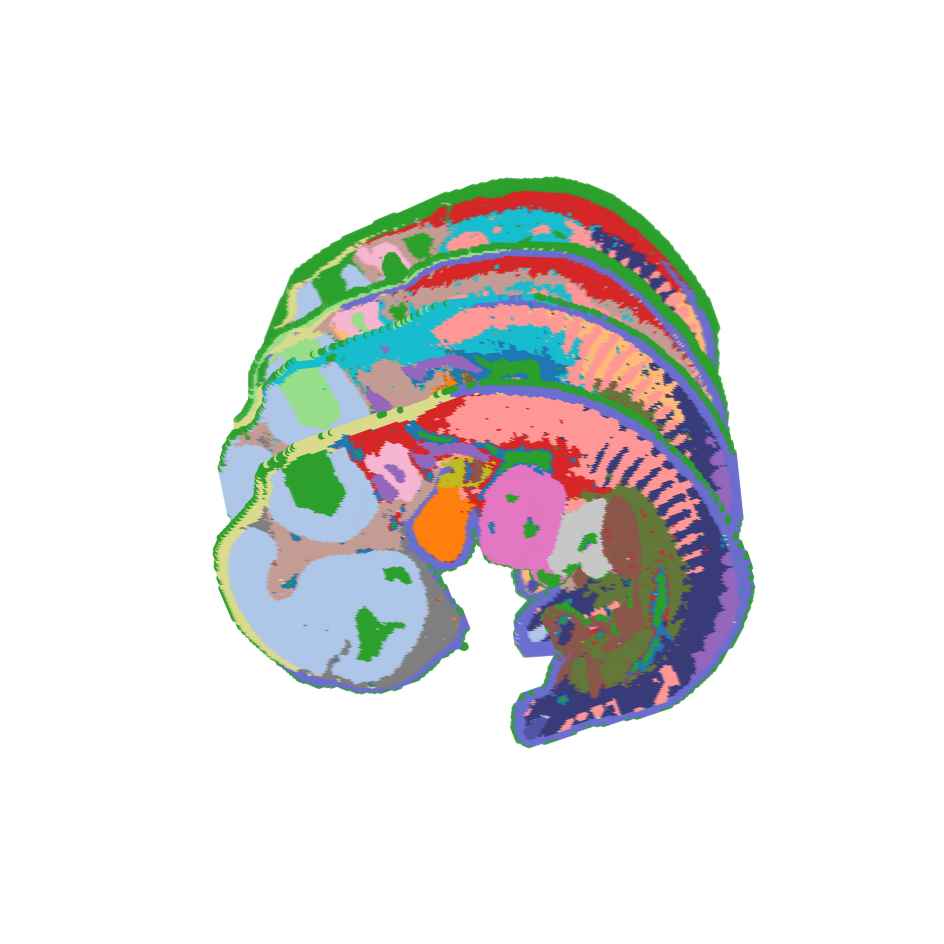

In [4]:
fig = plot_3d(coords.values, val=None, color=combined_df['celltype_colors'], elev=310, azim=0, roll=0, frameon=False, show=True, s=15, save_dpi=300, return_fig=True) # Scube is from SPACEL

fig.savefig('STalign_gtAndScube_embryo_E11.5_S1_S4_3dviz_angle310_0_0_s=15.pdf', bbox_inches="tight")